# 02 · Análisis exploratorio de las productoras

**Objetivo.** Entender cómo son las 138 productoras antes de definir indicadores: cómo se distribuyen sus variables, cómo se relacionan entre sí y en qué se diferencian Norandino y Bagua Grande.

**Estructura.** Preparación de variables, análisis univariado, bivariado y multivariado (PCA). Cada gráfico o tabla termina con una conclusión.

| | Archivo |
|---|---|
| Entrada | `data/processed/productoras_limpia.csv` (salida del notebook 01) |
| Salida | `data/processed/pca_productivo.csv` y `data/processed/hallazgos_exploracion.csv` |

**Cuidado al leer.** El área de café y el peso del quintal no tienen unidad confirmada, por eso nunca se convierten. Con solo 25 productoras en Bagua Grande, las diferencias pequeñas entre cooperativas pueden deberse al azar.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from matplotlib.ticker import FuncFormatter, MaxNLocator
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
OUT = ROOT / "data" / "processed"
FIG = ROOT / "docs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

COLORES = {"NORANDINO": "#2F5F9F", "BAGUA_GRANDE": "#8B5A2B"}
NOMBRES = {"NORANDINO": "Norandino", "BAGUA_GRANDE": "Bagua Grande"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
pd.set_option("display.width", 200, "display.max_columns", 30)

# Nombres legibles para las categorías que se muestran en los gráficos
ETIQ = {"FERTILIZACION": "Fertilización", "CRIANZA_CUYES": "Crianza de cuyes", "CRIANZA_GALLINAS": "Crianza de gallinas",
        "CRIANZA_CERDOS": "Crianza de cerdos", "MULTIPLE": "Varios destinos", "CAFE_TOSTADO_MOLIDO": "Café tostado y molido",
        "TECNICO_COMPLETO": "Técnico completo", "CONYUGE": "Cónyuge", "SOLO_LECTURA": "Solo lectura", "SOLO_ESCRITURA": "Solo escritura",
        "SIN_SENAL_SECTOR": "Sin señal en el sector", "FUERA_DE_CASA": "Fuera de casa", "EN_CASA": "En casa"}
def etiqueta(valor):
    return ETIQ.get(valor, str(valor).replace("_", " ").capitalize())

def fuente(fig, texto="Fuente: base de productoras limpia (138 productoras). Cálculo propio."):
    """Pie de fuente en cada figura."""
    fig.text(0.01, 0.0, texto, fontsize=8, color="#555")

base = pd.read_csv(OUT / "productoras_limpia.csv")
print("Productoras:", len(base), "| columnas:", base.shape[1])
print(base["cooperativa"].map(NOMBRES).value_counts().to_string())

Productoras: 138 | columnas: 75
cooperativa
Norandino       113
Bagua Grande     25


## 1. Preparación para el análisis

Se eligen las variables y se aplican tres transformaciones que se justifican a continuación.

| Transformación | Cómo | Por qué |
|---|---|---|
| Selección de variables | Siete variables numéricas y seis categóricas de interés | Responden a las cuatro preguntas del proyecto: conocer, decidir, acompañar y visitar |
| Creación de variables | Grupo de edad; acopio por unidad de área; monto solicitado sobre ingreso | Permiten comparar fincas de distinto tamaño y medir la carga relativa del crédito |
| Escalado | `StandardScaler` (media 0, desviación 1) solo dentro del PCA | El PCA mezcla variables con unidades distintas (años, quintales, soles); sin escalar, domina la de mayor magnitud |
| Codificación | Variables 1/0 ya incluidas en la base; las categorías se comparan como porcentajes | Una categoría no tiene distancia numérica con otra, no se promedia |

No se aplica logaritmo: se prefirió mantener las unidades originales para que los resultados se lean directamente.

In [2]:
NUM = {"edad_al_cierre_2025": "Edad (años)", "n_familiares_convivientes": "Familiares que viven con ella",
       "antiguedad_socio_titular_anios": "Antigüedad como socio (años)", "area_cafe_reportada": "Área de café (unidad por confirmar)",
       "quintales_acopiados_2025": "Quintales acopiados en 2025", "ingreso_principal_pen_2025": "Ingreso principal anual (S/)",
       "monto_solicitado_pen": "Monto solicitado (S/)"}

# Variable creada: grupo de edad
base["grupo_edad"] = pd.cut(base["edad_al_cierre_2025"], [0, 29, 39, 49, 59, 120],
                            labels=["Hasta 29", "30 a 39", "40 a 49", "50 a 59", "60 o más"])
# Variable creada: 1 si declara alguna dificultad para leer o escribir
base["dificultad_lecto"] = (base["dificultad_lectoescritura"] != "NINGUNA").astype(int)
print("Variables derivadas ya incluidas en la base:")
print(base[["acopio_por_unidad_area_2025", "monto_solicitado_sobre_ingreso_principal"]].describe().round(2).to_string())
print()
print(base["grupo_edad"].value_counts().sort_index().to_string())

Variables derivadas ya incluidas en la base:
       acopio_por_unidad_area_2025  monto_solicitado_sobre_ingreso_principal
count                       138.00                                    138.00
mean                         17.91                                      0.05
std                           6.81                                      0.03
min                           4.00                                      0.01
25%                          12.50                                      0.03
50%                          16.58                                      0.04
75%                          23.46                                      0.06
max                          43.00                                      0.22

grupo_edad
Hasta 29    24
30 a 39     32
40 a 49     41
50 a 59     33
60 o más     8


## 2. Análisis univariado

### 2.1 Variables numéricas

Se muestra cada distribución con su mediana (línea verde) y su media (línea punteada). Si la media queda lejos de la mediana, hay asimetría y conviene usar la mediana.

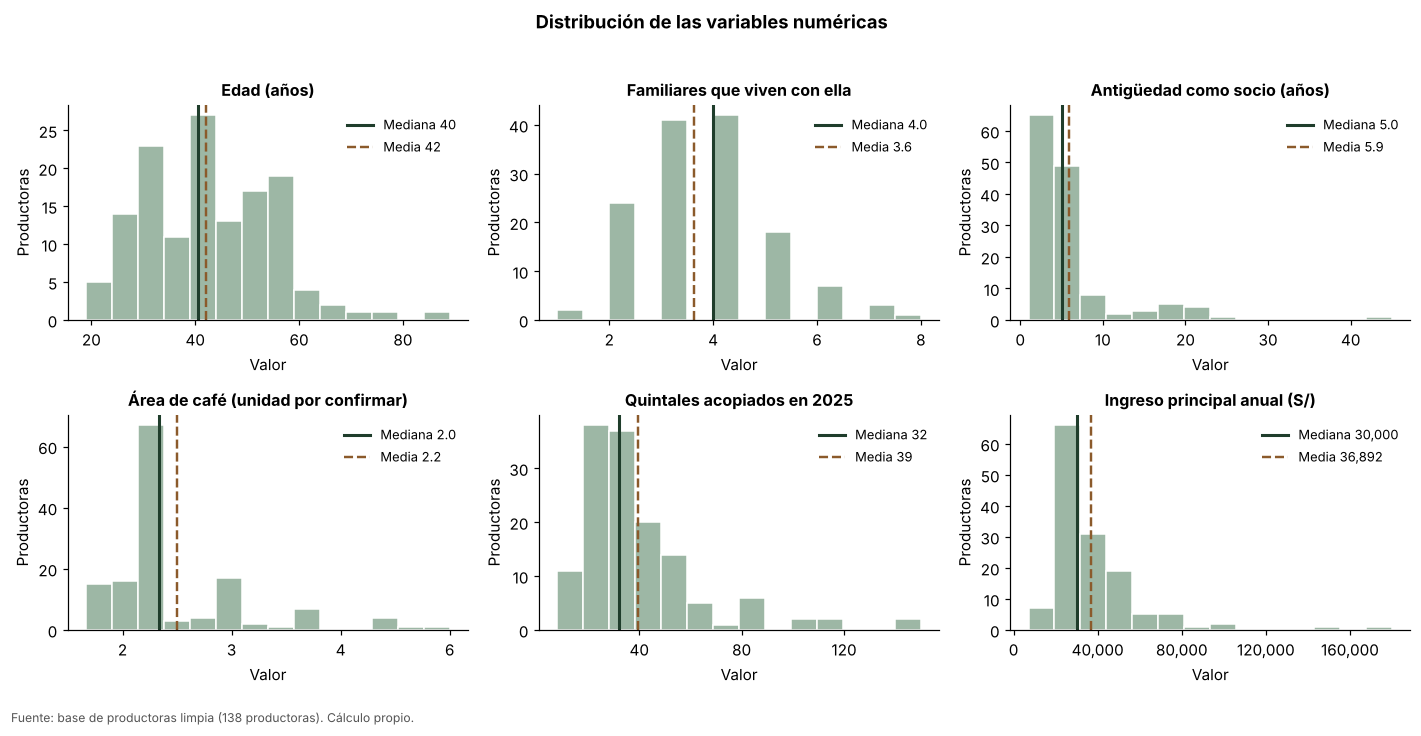

In [3]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 6.6))
for eje, var in zip(ejes.ravel(), list(NUM)[:6]):
    s = base[var]
    eje.hist(s, bins=14, color="#9DB7A5", edgecolor="white")
    eje.axvline(s.median(), color="#1F3D2B", linewidth=2, label=f"Mediana {s.median():,.0f}" if s.median() >= 10 else f"Mediana {s.median():.1f}")
    eje.axvline(s.mean(), color="#8B5A2B", linestyle="--", linewidth=1.6, label=f"Media {s.mean():,.0f}" if s.mean() >= 10 else f"Media {s.mean():.1f}")
    eje.set_title(NUM[var], fontsize=10.5)
    eje.set_xlabel("Valor")
    eje.set_ylabel("Productoras")
    eje.xaxis.set_major_locator(MaxNLocator(5))
    eje.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    eje.legend(frameon=False, fontsize=8.5)
fig.suptitle("Distribución de las variables numéricas", fontweight="bold")
fuente(fig)
plt.tight_layout(rect=(0, 0.03, 1, 0.96))
plt.savefig(FIG / "02_univariado_numericas.png", bbox_inches="tight")
plt.show()

In [4]:
resumen = base[list(NUM)].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T.round(2)
resumen.index = [NUM[i] for i in resumen.index]
resumen.rename(columns={"count": "n", "mean": "media", "median": "mediana", "std": "desv. est.", "min": "mínimo", "max": "máximo", "skew": "asimetría"})

,n,media,mediana,desv. est.,mínimo,máximo,asimetría
Edad (años),138.0,41.99,40.5,12.50,19.0,89.0,0.53
Familiares que viven con ella,138.0,3.64,4.0,1.28,1.0,8.0,0.64
Antigüedad como socio (años),138.0,5.88,5.0,5.95,1.0,45.0,3.12
Área de café (unidad por confirmar),138.0,2.25,2.0,0.96,1.0,6.0,1.53
Quintales acopiados en 2025,138.0,39.45,32.0,23.70,8.0,150.0,2.33
Ingreso principal anual (S/),138.0,36892.03,30000.0,22831.32,7100.0,180000.0,3.19
Monto solicitado (S/),138.0,1378.08,1375.0,209.48,500.0,2000.0,-0.34


**Conclusión.** Las variables de escala (quintales, ingreso, área y antigüedad) tienen asimetría positiva fuerte (entre 1.5 y 3.2): la mayoría de productoras son pequeñas y unas pocas son muy grandes, lo que jala la media hacia arriba. Por eso **la mediana representa mejor a la productora típica**: 32 quintales por productora y 2 unidades de área. La edad y el número de familiares son más simétricas (asimetría menor a 0.7), con una productora típica de unos 40 años.

### 2.2 Variables categóricas

Se compara el porcentaje de productoras en cada categoría para las preguntas de acceso y perfil.

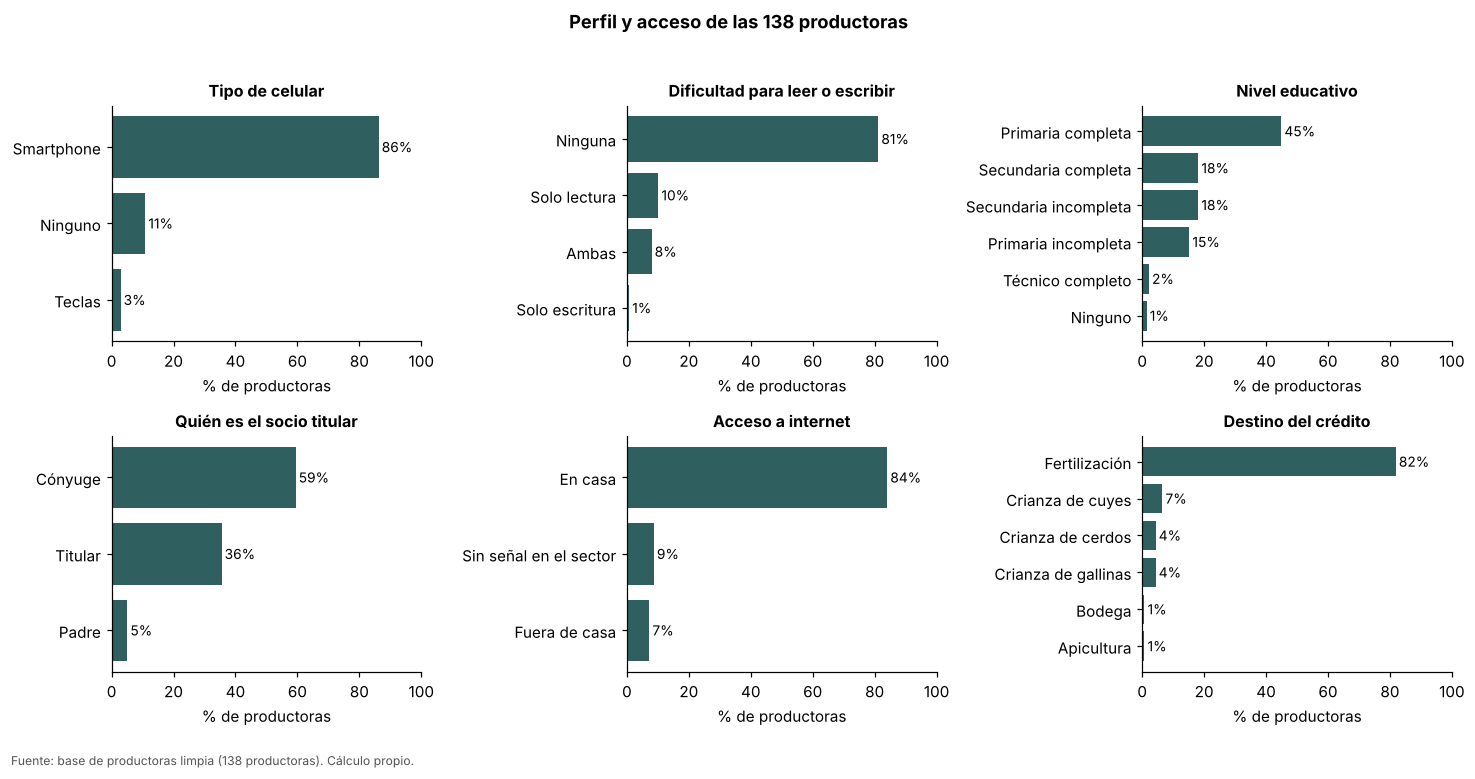

In [5]:
CAT = {"tipo_celular_beneficiaria": "Tipo de celular", "dificultad_lectoescritura": "Dificultad para leer o escribir",
       "nivel_educativo": "Nivel educativo", "parentesco_socio_titular": "Quién es el socio titular",
       "acceso_internet": "Acceso a internet", "grupo_destino_financiamiento": "Destino del crédito"}
fig, ejes = plt.subplots(2, 3, figsize=(13.5, 7))
for eje, (var, titulo) in zip(ejes.ravel(), CAT.items()):
    p = base[var].value_counts(normalize=True).mul(100).sort_values().tail(6)
    eje.barh([etiqueta(x) for x in p.index], p.values, color="#2F5F5F")
    for y, v in enumerate(p.values):
        eje.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9)
    eje.set_title(titulo, fontsize=10.5)
    eje.set_xlim(0, 100)
    eje.set_xlabel("% de productoras")
fig.suptitle("Perfil y acceso de las 138 productoras", fontweight="bold")
fuente(fig)
plt.tight_layout(rect=(0, 0.03, 1, 0.96))
plt.savefig(FIG / "02_univariado_categoricas.png", bbox_inches="tight")
plt.show()

**Conclusión.** La gran mayoría tiene smartphone (86 %) y no declara dificultad para leer o escribir (81 %); la primaria completa es el nivel educativo más frecuente (45 %). Aun así, **una de cada nueve no tiene celular y casi una de cada cinco tiene alguna dificultad de lectoescritura**, por lo que un canal solo escrito o solo digital dejaría fuera a una parte de las productoras. El 82 % pide el crédito para fertilización; el resto se reparte entre crianzas y otras actividades pequeñas.

## 3. Análisis bivariado

### 3.1 Dos variables numéricas: correlaciones

Se usa la correlación de Spearman, que mide si dos variables suben juntas sin suponer una relación recta y resiste los valores extremos.

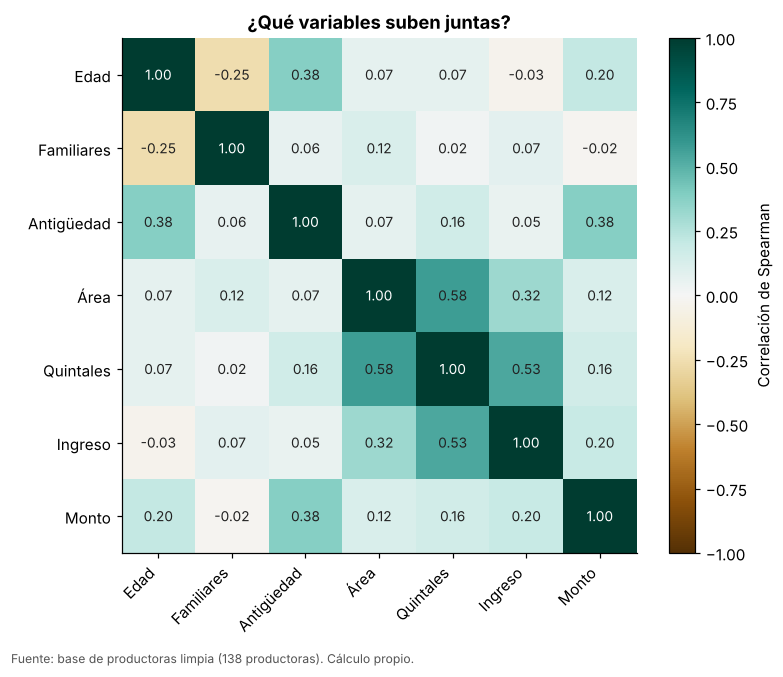

In [6]:
corr = base[list(NUM)].corr(method="spearman")
etiquetas = ["Edad", "Familiares", "Antigüedad", "Área", "Quintales", "Ingreso", "Monto"]
fig, eje = plt.subplots(figsize=(7.2, 6))
im = eje.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
eje.set_xticks(range(7), etiquetas, rotation=45, ha="right")
eje.set_yticks(range(7), etiquetas)
for i in range(7):
    for j in range(7):
        eje.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                 color="white" if abs(corr.iloc[i, j]) > 0.6 else "#222")
fig.colorbar(im, label="Correlación de Spearman")
eje.set_title("¿Qué variables suben juntas?")
fuente(fig)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "02_correlaciones.png", bbox_inches="tight")
plt.show()

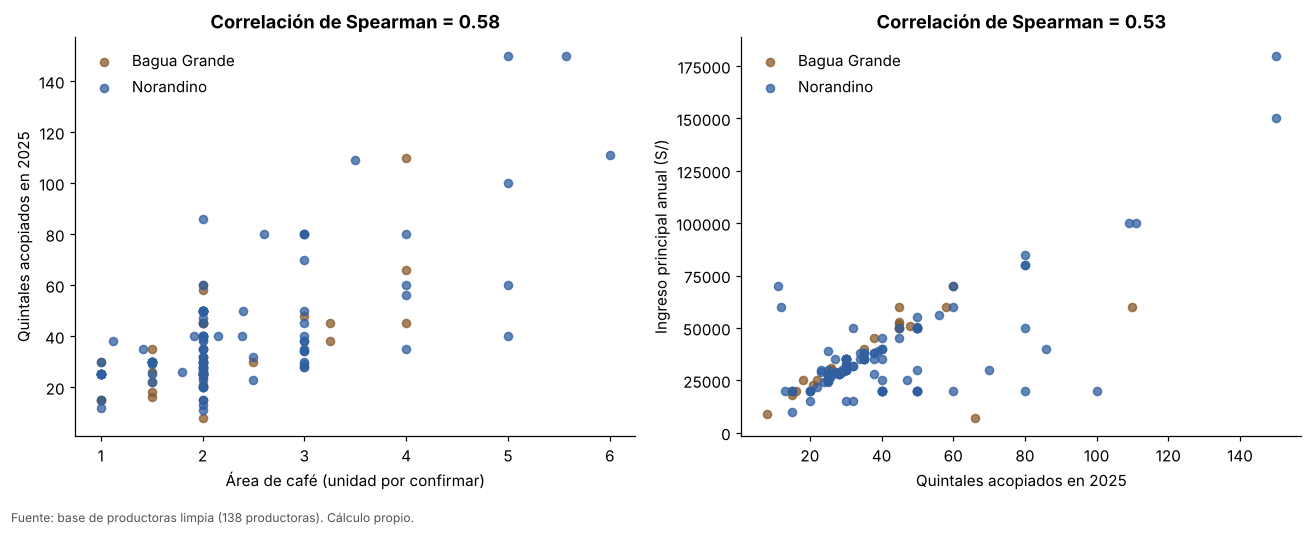

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
pares = [("area_cafe_reportada", "quintales_acopiados_2025", "Área de café (unidad por confirmar)", "Quintales acopiados en 2025"),
         ("quintales_acopiados_2025", "ingreso_principal_pen_2025", "Quintales acopiados en 2025", "Ingreso principal anual (S/)")]
for eje, (x, y, lx, ly) in zip(ejes, pares):
    for coop, d in base.groupby("cooperativa"):
        eje.scatter(d[x], d[y], s=28, alpha=0.75, color=COLORES[coop], label=NOMBRES[coop])
    rho, p = stats.spearmanr(base[x], base[y])
    eje.set_xlabel(lx)
    eje.set_ylabel(ly)
    eje.set_title(f"Correlación de Spearman = {rho:.2f}")
    eje.legend(frameon=False)
fuente(fig)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "02_dispersion.png", bbox_inches="tight")
plt.show()

**Conclusión.** Las tres variables de escala productiva se mueven juntas: **área y quintales** (0.58), **quintales e ingreso** (0.53) y, más débilmente, área e ingreso (0.32). Es lo esperable: más terreno, más café y más ingreso. El área no explica todo, porque hay fincas del mismo tamaño con acopios muy distintos. La edad no se relaciona con la escala productiva (correlaciones cercanas a cero). La correlación entre antigüedad y monto (0.38) viene de que las dos cooperativas piden montos distintos y tienen antigüedades distintas, no de una relación directa entre ellas.

### 3.2 Numérica contra categórica: Norandino frente a Bagua Grande

Se compara cada variable numérica entre cooperativas con la prueba de Mann-Whitney, que no exige que los datos sean simétricos. Un valor p menor a 0.05 indica una diferencia que probablemente no es casualidad.

In [8]:
filas = []
for var in ["edad_al_cierre_2025", "antiguedad_socio_titular_anios", "area_cafe_reportada", "quintales_acopiados_2025", "ingreso_principal_pen_2025"]:
    a = base.loc[base["cooperativa"] == "NORANDINO", var]
    b = base.loc[base["cooperativa"] == "BAGUA_GRANDE", var]
    filas.append({"variable": NUM[var], "mediana Norandino": a.median(), "mediana Bagua Grande": b.median(),
                  "valor p": stats.mannwhitneyu(a, b).pvalue, "tipo de prueba": "Mann-Whitney"})
num_coop = pd.DataFrame(filas).set_index("variable")
num_coop["¿diferencia clara?"] = np.where(num_coop["valor p"] < 0.05, "Sí", "No")
num_coop.round(4)

,mediana Norandino,mediana Bagua Grande,valor p,tipo de prueba,¿diferencia clara?
variable,,,,,
Edad (años),40.0,47.0,0.0250,Mann-Whitney,Sí
Antigüedad como socio (años),4.0,15.0,0.0000,Mann-Whitney,Sí
Área de café (unidad por confirmar),2.0,2.0,0.6249,Mann-Whitney,No
Quintales acopiados en 2025,32.0,30.0,0.5813,Mann-Whitney,No
Ingreso principal anual (S/),30000.0,35000.0,0.4590,Mann-Whitney,No


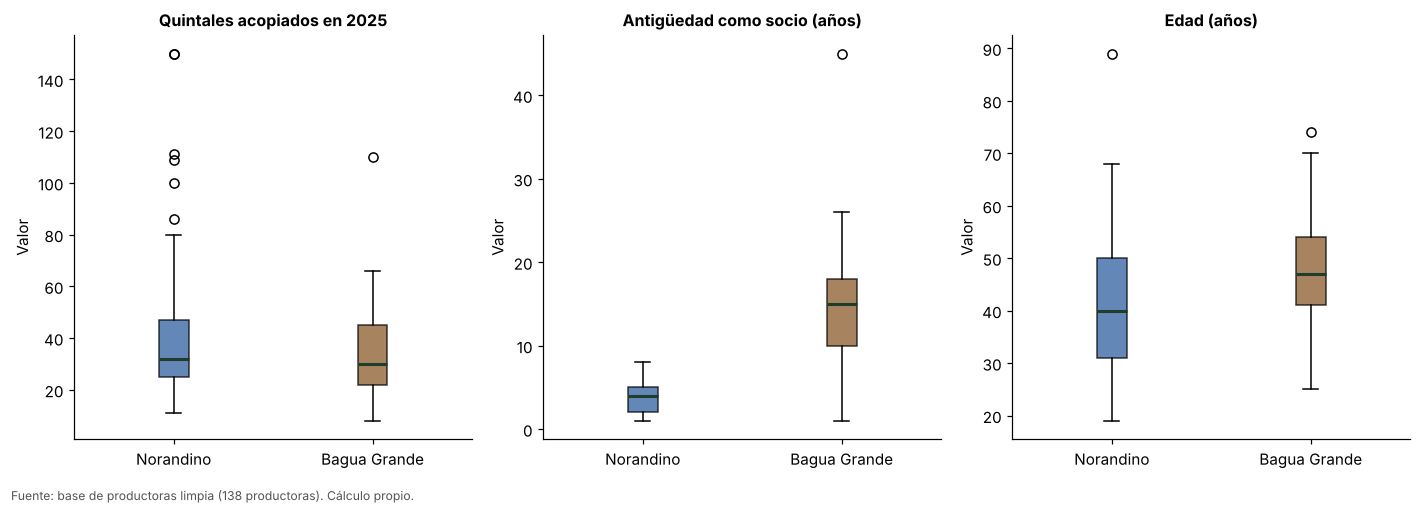

In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4.6))
for eje, var in zip(ejes, ["quintales_acopiados_2025", "antiguedad_socio_titular_anios", "edad_al_cierre_2025"]):
    datos = [base.loc[base["cooperativa"] == c, var] for c in COLORES]
    caja = eje.boxplot(datos, tick_labels=[NOMBRES[c] for c in COLORES], patch_artist=True, medianprops={"color": "#1F3D2B", "linewidth": 2})
    for parche, c in zip(caja["boxes"], COLORES):
        parche.set_facecolor(COLORES[c])
        parche.set_alpha(0.75)
    eje.set_title(NUM[var], fontsize=10.5)
    eje.set_ylabel("Valor")
fuente(fig)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "02_cajas_por_cooperativa.png", bbox_inches="tight")
plt.show()

**Conclusión.** En escala productiva **las dos cooperativas son parecidas**: quintales, área e ingreso no difieren de forma clara (p entre 0.46 y 0.62). Donde sí difieren es en el perfil de la socia: en Bagua Grande la antigüedad típica es de 15 años y en Norandino de 4 (diferencia muy clara), y las productoras de Bagua Grande son algo mayores (47 contra 40 años, p = 0.025). Es decir, Bagua Grande agrupa socias de larga trayectoria y Norandino, socias más recientes.

### 3.3 Dos variables categóricas: acceso y servicios por cooperativa

Se cruza la cooperativa con seis preguntas de sí/no y se aplica la prueba exacta de Fisher, apropiada para tablas pequeñas.

In [10]:
SINO = {"smartphone_propio": "Tiene smartphone", "dificultad_lecto": "Tiene dificultad para leer o escribir",
        "capacitacion_cooperativa_2025": "Recibió capacitación de la cooperativa",
        "declara_ningun_servicio_financiero": "No usa ningún servicio financiero",
        "internet_en_casa": "Tiene internet en casa", "tiene_electricidad": "Tiene electricidad"}
filas = []
for var, etiqueta in SINO.items():
    d = base[["cooperativa", var]].dropna()
    tabla = pd.crosstab(d["cooperativa"], d[var])
    p = stats.fisher_exact(tabla.values)[1]
    filas.append({"pregunta": etiqueta, "% Norandino": 100 * d.loc[d["cooperativa"] == "NORANDINO", var].mean(),
                  "% Bagua Grande": 100 * d.loc[d["cooperativa"] == "BAGUA_GRANDE", var].mean(),
                  "n respondieron": len(d), "valor p": p})
acceso = pd.DataFrame(filas).set_index("pregunta")
acceso["¿diferencia clara?"] = np.where(acceso["valor p"] < 0.05, "Sí", "No")
acceso.round(3)

,% Norandino,% Bagua Grande,n respondieron,valor p,¿diferencia clara?
pregunta,,,,,
Tiene smartphone,88.496,76.000,138,0.114,No
Tiene dificultad para leer o escribir,23.009,0.000,138,0.004,Sí
Recibió capacitación de la cooperativa,85.841,88.000,138,1.000,No
No usa ningún servicio financiero,87.611,29.167,137,0.000,Sí
Tiene internet en casa,86.726,72.000,138,0.078,No
Tiene electricidad,98.230,100.000,138,1.000,No


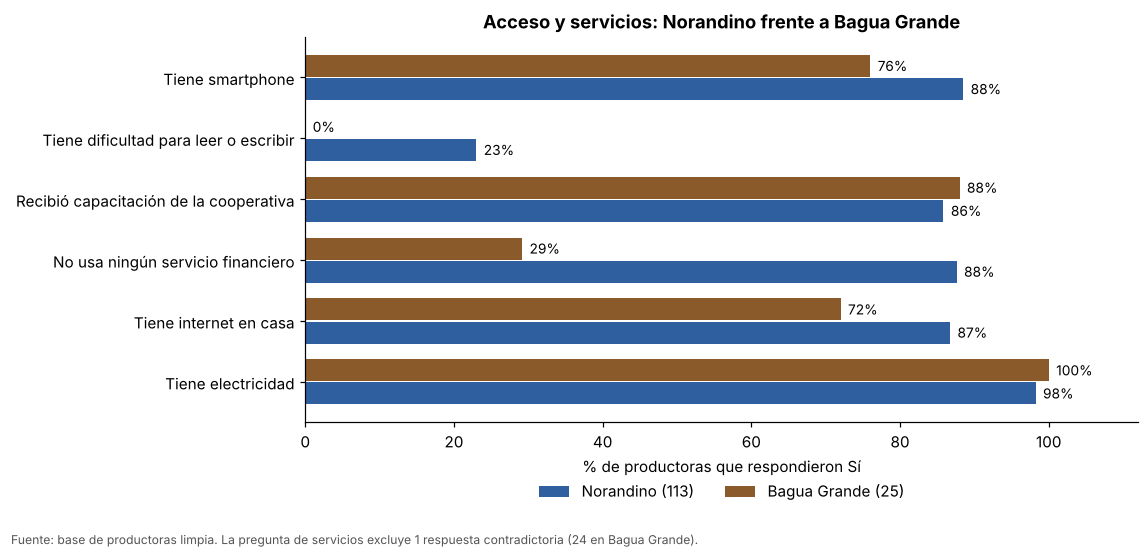

In [11]:
fig, eje = plt.subplots(figsize=(10.5, 5))
y = np.arange(len(acceso))
eje.barh(y + 0.19, acceso["% Norandino"], height=0.36, color=COLORES["NORANDINO"], label="Norandino (113)")
eje.barh(y - 0.19, acceso["% Bagua Grande"], height=0.36, color=COLORES["BAGUA_GRANDE"], label="Bagua Grande (25)")
for i, (a, b) in enumerate(zip(acceso["% Norandino"], acceso["% Bagua Grande"])):
    eje.text(a + 1, i + 0.19, f"{a:.0f}%", va="center", fontsize=9)
    eje.text(b + 1, i - 0.19, f"{b:.0f}%", va="center", fontsize=9)
eje.set_yticks(y, acceso.index)
eje.invert_yaxis()
eje.set_xlim(0, 112)
eje.set_xlabel("% de productoras que respondieron Sí")
eje.set_title("Acceso y servicios: Norandino frente a Bagua Grande")
eje.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
fuente(fig, "Fuente: base de productoras limpia. La pregunta de servicios excluye 1 respuesta contradictoria (24 en Bagua Grande).")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "02_acceso_por_cooperativa.png", bbox_inches="tight")
plt.show()

**Conclusión.** Hay dos diferencias claras entre cooperativas. **Servicios financieros:** el 88 % de las productoras de Norandino no usa ninguno, frente al 29 % en Bagua Grande (p < 0.001); allí casi todas usan al menos Yape. **Lectura:** en Norandino el 23 % declara alguna dificultad para leer o escribir y en Bagua Grande nadie (p = 0.004). En smartphone (88 % y 76 %) e internet en casa (87 % y 72 %) Norandino queda mejor, pero con 25 productoras en Bagua Grande esa diferencia **no es concluyente** (p cerca de 0.1). La capacitación (86 % y 88 %) y la electricidad (98 % y 100 %) son casi iguales. Implicación: el acompañamiento no debería ser idéntico en las dos cooperativas.

## 4. Análisis multivariado: PCA

El análisis de componentes principales resume varias variables correlacionadas en pocas dimensiones. Aquí se usa de forma **exploratoria**, para ver qué variables se mueven juntas; los componentes no son una puntuación de mérito ni de riesgo.

Se prueban dos bloques, escalando las variables (media 0 y desviación 1) dentro de cada bloque:

- **Bloque productivo** (3 variables): área, quintales e ingreso principal.
- **Bloque integral** (6 variables): las tres anteriores más edad, familiares que viven con ella y antigüedad como socio.

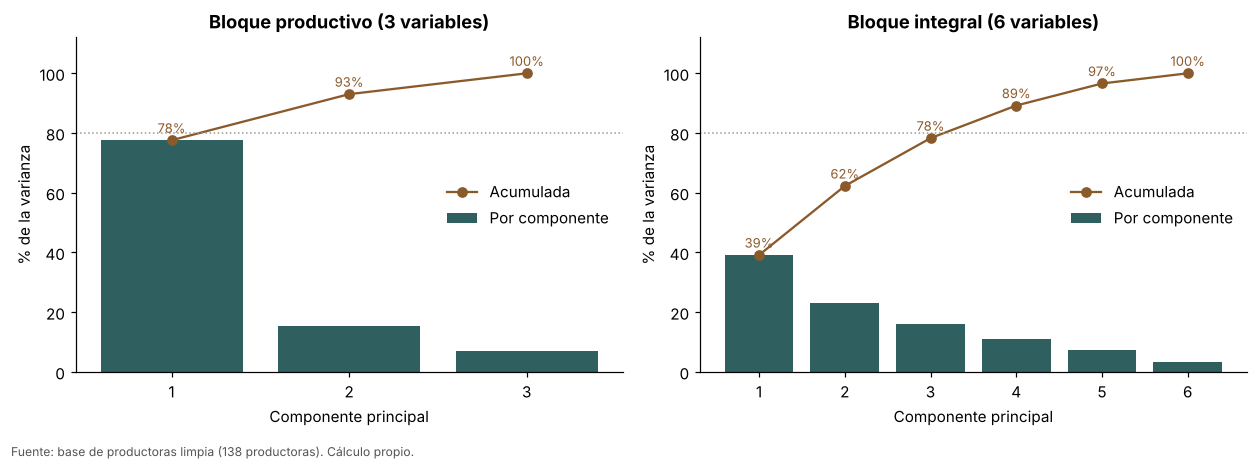

In [12]:
BLOQUES = {"productivo": ["area_cafe_reportada", "quintales_acopiados_2025", "ingreso_principal_pen_2025"],
           "integral": ["edad_al_cierre_2025", "n_familiares_convivientes", "antiguedad_socio_titular_anios",
                        "area_cafe_reportada", "quintales_acopiados_2025", "ingreso_principal_pen_2025"]}
modelos = {}
for nombre, cols in BLOQUES.items():
    z = StandardScaler().fit_transform(base[cols])      # escalado dentro del bloque
    pca = PCA().fit(z)
    modelos[nombre] = (pca, pca.transform(z), cols)

fig, ejes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for eje, (nombre, (pca, _, cols)) in zip(ejes, modelos.items()):
    v = pca.explained_variance_ratio_ * 100
    eje.bar(range(1, len(v) + 1), v, color="#2F5F5F", label="Por componente")
    eje.plot(range(1, len(v) + 1), v.cumsum(), color="#8B5A2B", marker="o", label="Acumulada")
    eje.axhline(80, color="#999", linestyle=":", linewidth=1)
    for i, val in enumerate(v.cumsum(), 1):
        eje.text(i, val + 2.5, f"{val:.0f}%", ha="center", fontsize=8.5, color="#8B5A2B")
    eje.set_ylim(0, 112)
    eje.set_xticks(range(1, len(v) + 1))
    eje.set_xlabel("Componente principal")
    eje.set_ylabel("% de la varianza")
    eje.set_title(f"Bloque {nombre} ({len(cols)} variables)")
    eje.legend(frameon=False, loc="center right")
fuente(fig)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "02_pca_varianza.png", bbox_inches="tight")
plt.show()

In [13]:
# Pesos (cargas) de cada variable en los tres primeros componentes
for nombre, (pca, _, cols) in modelos.items():
    cargas = pd.DataFrame(pca.components_[:3].T, index=cols, columns=["PC1", "PC2", "PC3"]).round(2)
    print(f"Bloque {nombre}: varianza explicada por componente (%):", (pca.explained_variance_ratio_ * 100).round(1).tolist())
    print(cargas.to_string(), "\n")

# Control: coincide con la hoja PCA_bloques de la base de referencia
ref_pca = pd.read_excel(OUT / "Base_Nor_BG_limpia.xlsx", sheet_name="PCA_bloques")
esperado = {"productivo": "productivo_economico", "integral": "integral_cuantitativo"}
for nombre, hoja in esperado.items():
    fila = ref_pca[ref_pca["bloque"] == hoja].iloc[0]
    aqui = modelos[nombre][0].explained_variance_ratio_ * 100
    print(f"{nombre}: PC1 aquí {aqui[0]:.2f}% / referencia {fila['PC1_pct']:.2f}% | PC1+PC2 aquí {aqui[:2].sum():.2f}% / referencia {fila['PC1_PC2_pct']:.2f}%")
    assert abs(aqui[0] - fila["PC1_pct"]) < 0.01 and abs(aqui[:2].sum() - fila["PC1_PC2_pct"]) < 0.01

Bloque productivo: varianza explicada por componente (%): [77.6, 15.4, 7.0]
                             PC1   PC2   PC3
area_cafe_reportada         0.55  0.76 -0.35
quintales_acopiados_2025    0.61 -0.08  0.79
ingreso_principal_pen_2025  0.57 -0.65 -0.51 

Bloque integral: varianza explicada por componente (%): [39.1, 23.1, 16.0, 10.9, 7.4, 3.4]
                                 PC1   PC2   PC3
edad_al_cierre_2025             0.10  0.68  0.02
n_familiares_convivientes       0.04 -0.50  0.74
antiguedad_socio_titular_anios  0.07  0.53  0.66
area_cafe_reportada             0.55 -0.07  0.03
quintales_acopiados_2025        0.60 -0.02 -0.11
ingreso_principal_pen_2025      0.56 -0.06 -0.06 



productivo: PC1 aquí 77.58% / referencia 77.58% | PC1+PC2 aquí 93.02% / referencia 93.02%
integral: PC1 aquí 39.14% / referencia 39.14% | PC1+PC2 aquí 62.27% / referencia 62.27%


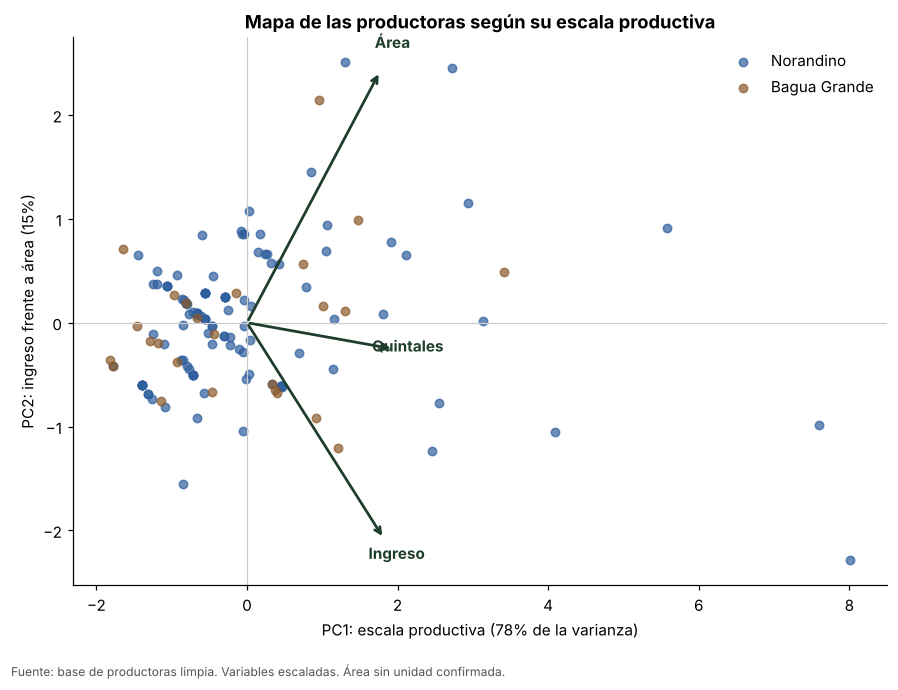

In [14]:
pca, puntos, cols = modelos["productivo"]
fig, eje = plt.subplots(figsize=(8.2, 6.2))
for coop in COLORES:
    m = (base["cooperativa"] == coop).values
    eje.scatter(puntos[m, 0], puntos[m, 1], s=30, alpha=0.7, color=COLORES[coop], label=NOMBRES[coop])
nombres_cortos = {"area_cafe_reportada": "Área", "quintales_acopiados_2025": "Quintales", "ingreso_principal_pen_2025": "Ingreso"}
for i, c in enumerate(cols):
    eje.annotate("", xy=(pca.components_[0, i] * 3.2, pca.components_[1, i] * 3.2), xytext=(0, 0),
                 arrowprops={"arrowstyle": "->", "color": "#1F3D2B", "linewidth": 1.8})
    eje.text(pca.components_[0, i] * 3.5, pca.components_[1, i] * 3.5, nombres_cortos[c], color="#1F3D2B", fontweight="bold", ha="center")
v = pca.explained_variance_ratio_ * 100
eje.set_xlabel(f"PC1: escala productiva ({v[0]:.0f}% de la varianza)")
eje.set_ylabel(f"PC2: ingreso frente a área ({v[1]:.0f}%)")
eje.axhline(0, color="#ccc", linewidth=0.8)
eje.axvline(0, color="#ccc", linewidth=0.8)
eje.set_title("Mapa de las productoras según su escala productiva")
eje.legend(frameon=False)
fuente(fig, "Fuente: base de productoras limpia. Variables escaladas. Área sin unidad confirmada.")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "02_pca_mapa.png", bbox_inches="tight")
plt.show()

**Conclusión del PCA.**

- **Bloque productivo.** Un solo componente reúne el 78 % de la información y dos componentes el 93 %. El primero (PC1) tiene peso positivo y parecido en área, quintales e ingreso: mide **escala productiva**, de pequeñas a grandes productoras. El segundo (PC2) opone área e ingreso: separa a quienes obtienen más ingreso del que su área haría esperar. Las flechas del gráfico apuntan en la misma dirección, y las dos cooperativas se mezclan en el mismo plano, lo que confirma que **su escala productiva es parecida**.
- **Bloque integral.** Al agregar edad, familiares y antigüedad, el primer componente baja a 39 % y hacen falta cuatro componentes para pasar el 80 %. Las variables demográficas no se resumen bien junto con las productivas: el segundo componente reúne edad y antigüedad frente a número de familiares (trayectoria de la socia), y el tercero combina familiares y antigüedad. **No conviene forzar un índice único**: se mantienen los indicadores por separado.
- **Límite.** El área y el quintal no tienen unidad confirmada, por lo que la comparación conjunta es provisional.

In [15]:
# Se guardan los resultados que se citan en el informe
salida = pd.DataFrame(modelos["productivo"][1][:, :2], columns=["PC1_productivo", "PC2_productivo"])
salida.insert(0, "cooperativa", base["cooperativa"])
salida.insert(0, "codigo_productora", base["codigo_productora"])
salida.to_csv(OUT / "pca_productivo.csv", index=False, encoding="utf-8-sig")

hallazgos = pd.concat([
    num_coop.reset_index().rename(columns={"variable": "tema"}).assign(prueba="Mann-Whitney")[["tema", "prueba", "valor p", "¿diferencia clara?"]],
    acceso.reset_index().rename(columns={"pregunta": "tema"}).assign(prueba="Fisher")[["tema", "prueba", "valor p", "¿diferencia clara?"]],
], ignore_index=True)
hallazgos.to_csv(OUT / "hallazgos_exploracion.csv", index=False, encoding="utf-8-sig")
hallazgos.round(4)

,tema,prueba,valor p,¿diferencia clara?
0,Edad (años),Mann-Whitney,0.0250,Sí
1,Antigüedad como socio (años),Mann-Whitney,0.0000,Sí
2,Área de café (unidad por confirmar),Mann-Whitney,0.6249,No
3,Quintales acopiados en 2025,Mann-Whitney,0.5813,No
4,Ingreso principal anual (S/),Mann-Whitney,0.4590,No
5,Tiene smartphone,Fisher,0.1141,No
6,Tiene dificultad para leer o escribir,Fisher,0.0041,Sí
7,Recibió capacitación de la cooperativa,Fisher,1.0000,No
8,No usa ningún servicio financiero,Fisher,0.0000,Sí
9,Tiene internet en casa,Fisher,0.0778,No


## 5. Hallazgos principales

1. **Las productoras son pequeñas y con gran dispersión.** La mediana es de 32 quintales y 2 unidades de área; unas pocas fincas muy grandes elevan los promedios. Por eso los indicadores usan la mediana.
2. **La escala productiva es parecida entre cooperativas.** Quintales, área e ingreso no difieren de forma clara; el PCA lo confirma con una sola dimensión de escala.
3. **Las cooperativas difieren en el perfil, no en la escala.** Bagua Grande tiene socias con más antigüedad (15 frente a 4 años) y algo mayores.
4. **El acceso a servicios financieros es la brecha más grande.** 88 % de Norandino no usa ninguno, frente a 29 % en Bagua Grande.
5. **Un canal solo escrito o solo digital deja fuera a una parte de las productoras.** Una de cada nueve no tiene celular y casi una de cada cinco tiene dificultades de lectoescritura, todas en Norandino.

**Limitaciones.** Bagua Grande tiene 25 productoras: las diferencias pequeñas no son concluyentes. Los datos son declarados y de un solo corte, no miden mora ni desembolsos, y el área y el quintal no tienen unidad confirmada.

**Siguiente:** `03_indicadores.ipynb` convierte estos hallazgos en indicadores definidos para Producers Direct.